In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl
import ast
import scipy
import mdtraj as md

# matplotlib settings
# --- Publication style settings ---
plt.rcParams.update({
    # Font
    "font.family": "serif",
    "font.serif": ["Times New Roman", "Times", "DejaVu Serif"],
    "mathtext.fontset": "stix",
    "text.usetex": False,

    # Editable, Affinity-compatible font embedding
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
    "svg.fonttype": "none",

    # Figure
    "figure.figsize": (6, 4),
    "figure.dpi": 150,

    # Axes
    "axes.titlesize": 12,
    "axes.labelsize": 10,
    "axes.linewidth": 1.2,
    "axes.grid": True,
    "grid.linestyle": "--",
    "grid.alpha": 0.7,

    # Ticks
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "xtick.direction": "in",
    "ytick.direction": "in",
    "xtick.top": True,
    "ytick.right": True,

    # Lines
    "lines.linewidth": 2,
    "lines.markersize": 6,

    # Legend
    "legend.fontsize": 10,
    "legend.frameon": False
})

# --- Utility functions ---
def RMSE(actual, predicted):
    actual = np.array(actual)
    predicted = np.array(predicted)
    return np.sqrt(np.mean((actual - predicted)**2))

def load_pf_data(protein, model_name, ensemble_dir="MD_DATA", exp_dir="EXP_DATA/PF_Nguyen_2018"):
    exp = pd.read_csv(f"../../{exp_dir}/{protein}.csv")
    residues = np.loadtxt(f"../../{ensemble_dir}/{protein}/{model_name}/exp_residues.txt")
    priorPF = np.exp(np.loadtxt(f"../../{ensemble_dir}/{protein}/{model_name}/prior_lnPF.txt"))
    if model_name in ('rewBV2006', 'rewBV2006ang'):
        rewPF = np.exp(np.loadtxt(f"../../{ensemble_dir}/{protein}/{model_name}/rew_lnPF.txt"))
        stats = pd.read_csv(f"../../{ensemble_dir}/{protein}/{model_name}/stats_df.csv")
        rewdata = np.loadtxt(f"../../{ensemble_dir}/{protein}/{model_name}/reweighting_chi2_phi_theta.txt")
    else:
        rewPF = np.exp(np.loadtxt(f"../../{ensemble_dir}/{protein}/{model_name}/log_lambda_rew_lnPF.txt"))
        stats = pd.read_csv(f"../../{ensemble_dir}/{protein}/{model_name}/log_lambda_stats_df.csv")
        rewdata = np.loadtxt(f"../../{ensemble_dir}/{protein}/{model_name}/log_lambda_reweighting_chi2_phi_theta.txt")
    chi2, phi, thetas = rewdata[0, :], rewdata[1, :], rewdata[2, :]
    idxs = [list(exp["Model_residue"]).index(ele) for ele in residues]
    return exp, residues, priorPF, rewPF, chi2, phi, thetas, stats, idxs

def find_elbow(x, y):
    # Convert to numpy arrays
    x = np.array(x)
    y = np.array(y)

    # Sort x (and y) if needed, but keep track of original indices
    if not np.all(np.diff(x) >= 0):
        idx_sort = np.argsort(x)
        x_sorted = x[idx_sort]
        y_sorted = y[idx_sort]
    else:
        idx_sort = np.arange(len(x))
        x_sorted, y_sorted = x, y

    # Line between first and last point
    p1 = np.array([x_sorted[0], y_sorted[0]])
    p2 = np.array([x_sorted[-1], y_sorted[-1]])
    line_vec = p2 - p1
    line_vec_norm = line_vec / np.linalg.norm(line_vec)

    # Distances from each point to the line
    vec_from_p1 = np.vstack([x_sorted - p1[0], y_sorted - p1[1]]).T
    proj_len = np.dot(vec_from_p1, line_vec_norm)
    proj_point = np.outer(proj_len, line_vec_norm) + p1
    dist = np.linalg.norm(vec_from_p1 - (proj_point - p1), axis=1)

    # Elbow = point with maximum distance
    idx_elbow_sorted = np.argmax(dist)
    idx_elbow_original = idx_sort[idx_elbow_sorted]

    return idx_elbow_original, x[idx_elbow_original], y[idx_elbow_original]

# Function to calculate helical fraction
def helical_fraction(ss_line):
    helix_chars = {'H', 'G', 'I'}
    n_residues = len(ss_line)
    n_helical = sum(1 for c in ss_line if c in helix_chars)
    return n_helical / n_residues

# Function to calculate per-residue helicity per frame
def dssp_to_helicity(dssp_lines):
    """
    Convert DSSP strings into a binary helicity matrix.
    
    Parameters
    ----------
    dssp_lines : list of str
        Each entry corresponds to one frame.
        Each string is the DSSP assignment per residue for that frame.
    
    Returns
    -------
    helicity : np.ndarray
        Array of shape (n_frames, n_residues).
        1 = helix ('H', 'G', 'I'), 0 = non-helix.
    """
    helix_codes = {'H', 'G', 'I'}
    
    n_frames = len(dssp_lines)
    n_residues = len(dssp_lines[0])
    
    helicity = np.zeros((n_frames, n_residues), dtype=int)
    
    for i, line in enumerate(dssp_lines):
        helicity[i, :] = [1 if c in helix_codes else 0 for c in line]
    
    return helicity


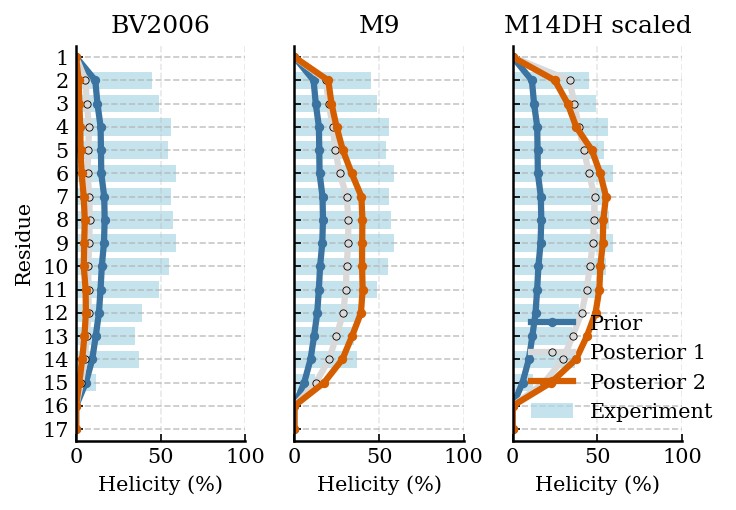

In [ ]:
# --------------------------------------------------
# Models and protein
# --------------------------------------------------
models = ["rewBV2006", "rewM9", "rewM14DH_scaled"]
model_labels = ["BV2006", "M9", "M14DH scaled"]
protein = "AAQAA3"

# --------------------------------------------------
# Colours
# --------------------------------------------------
COLOR3 = "#3B73A1"  # prior
COLOR2 = "#D55E00"  # posterior 1: elbow
COLOR1 = "#D9D9D9"  # posterior 2
EXP_COLOR = "lightblue"

# --------------------------------------------------
# Load DSSP data
# --------------------------------------------------
with open(f"../../MD_DATA/{protein}/dssp.dat") as f:
    dssp = np.array([line.strip() for line in f])

H = dssp_to_helicity(dssp) * 100
all_residues = np.arange(1, H.shape[1] + 1)

# --------------------------------------------------
# Load experimental helicity
# --------------------------------------------------
exp_helix = np.loadtxt(f"../../ORTHOGONAL_EXP_DATA/{protein}/helicity.dat")
exp_helix_residues = exp_helix[:, 0].astype(int)
exp_helix_values = exp_helix[:, 1]

# --------------------------------------------------
# Create figure
# --------------------------------------------------
fig, axes = plt.subplots(1, 3, figsize=(5, 3.5), sharex=True, sharey=True)

for ax, model, model_label in zip(axes, models, model_labels):

    model_dir = f"../../MD_DATA/{protein}/{model}"

    if "BV" in model:
        elbow_weights_file = f"{model_dir}/wopt_elbow.npy"
        weights_file = f"{model_dir}/wopt.npy"
    else:
        elbow_weights_file = f"{model_dir}/log_lambda_wopt_elbow.npy"
        weights_file = f"{model_dir}/log_lambda_wopt.npy"

    wopt_elbow = np.load(elbow_weights_file)
    wopt = np.load(weights_file)

    prior_helicity = np.mean(H, axis=0)
    posterior1_helicity = np.average(H, weights=wopt_elbow, axis=0)
    posterior2_helicity = np.average(H, weights=wopt, axis=0)

    ax.barh(exp_helix_residues, exp_helix_values, height=0.75, color=EXP_COLOR, alpha=0.7, label="Experiment")
    ax.plot(prior_helicity, all_residues, color=COLOR3, linewidth=3, marker="o", markersize=3.5, label="Prior")
    ax.plot(posterior1_helicity, all_residues, color=COLOR1, linewidth=3, marker="o", markersize=3.5, markeredgecolor="black", markeredgewidth=0.4, label="Posterior 1")
    ax.plot(posterior2_helicity, all_residues, color=COLOR2, linewidth=3, marker="o", markersize=3.5, label="Posterior 2")

    ax.set_title(model_label)
    ax.set_xlabel("Helicity (%)")
    ax.set_xlim(0, 100)
    ax.set_ylim(H.shape[1] + 0.5, 0.5)
    ax.set_yticks(np.arange(1, H.shape[1] + 1))
    ax.grid(axis="x", alpha=0.3)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.tick_params(axis="both", top=False, right=False)

axes[0].set_ylabel("Residue")
axes[-1].legend(loc="best", frameon=False)

plt.tight_layout()
plt.savefig(f"AAQAA3_plots/{protein}_helicity_BV2006_M9_M14DH_scaled.pdf", dpi=300, bbox_inches="tight")
plt.show()

/tmp/ipykernel_901441/2201677832.py:57: UserWarning: Attempted to set non-positive bottom ylim on a log-scaled axis.
Invalid limit will be ignored.
  ax.set_ylim(0,15)
/tmp/ipykernel_901441/2201677832.py:57: UserWarning: Attempted to set non-positive bottom ylim on a log-scaled axis.
Invalid limit will be ignored.
  ax.set_ylim(0,15)
/tmp/ipykernel_901441/2201677832.py:57: UserWarning: Attempted to set non-positive bottom ylim on a log-scaled axis.
Invalid limit will be ignored.
  ax.set_ylim(0,15)
/tmp/ipykernel_901441/2201677832.py:57: UserWarning: Attempted to set non-positive bottom ylim on a log-scaled axis.
Invalid limit will be ignored.
  ax.set_ylim(0,15)
/tmp/ipykernel_901441/2201677832.py:57: UserWarning: Attempted to set non-positive bottom ylim on a log-scaled axis.
Invalid limit will be ignored.
  ax.set_ylim(0,15)
/tmp/ipykernel_901441/2201677832.py:57: UserWarning: Attempted to set non-positive bottom ylim on a log-scaled axis.
Invalid limit will be ignored.
  ax.set_yli

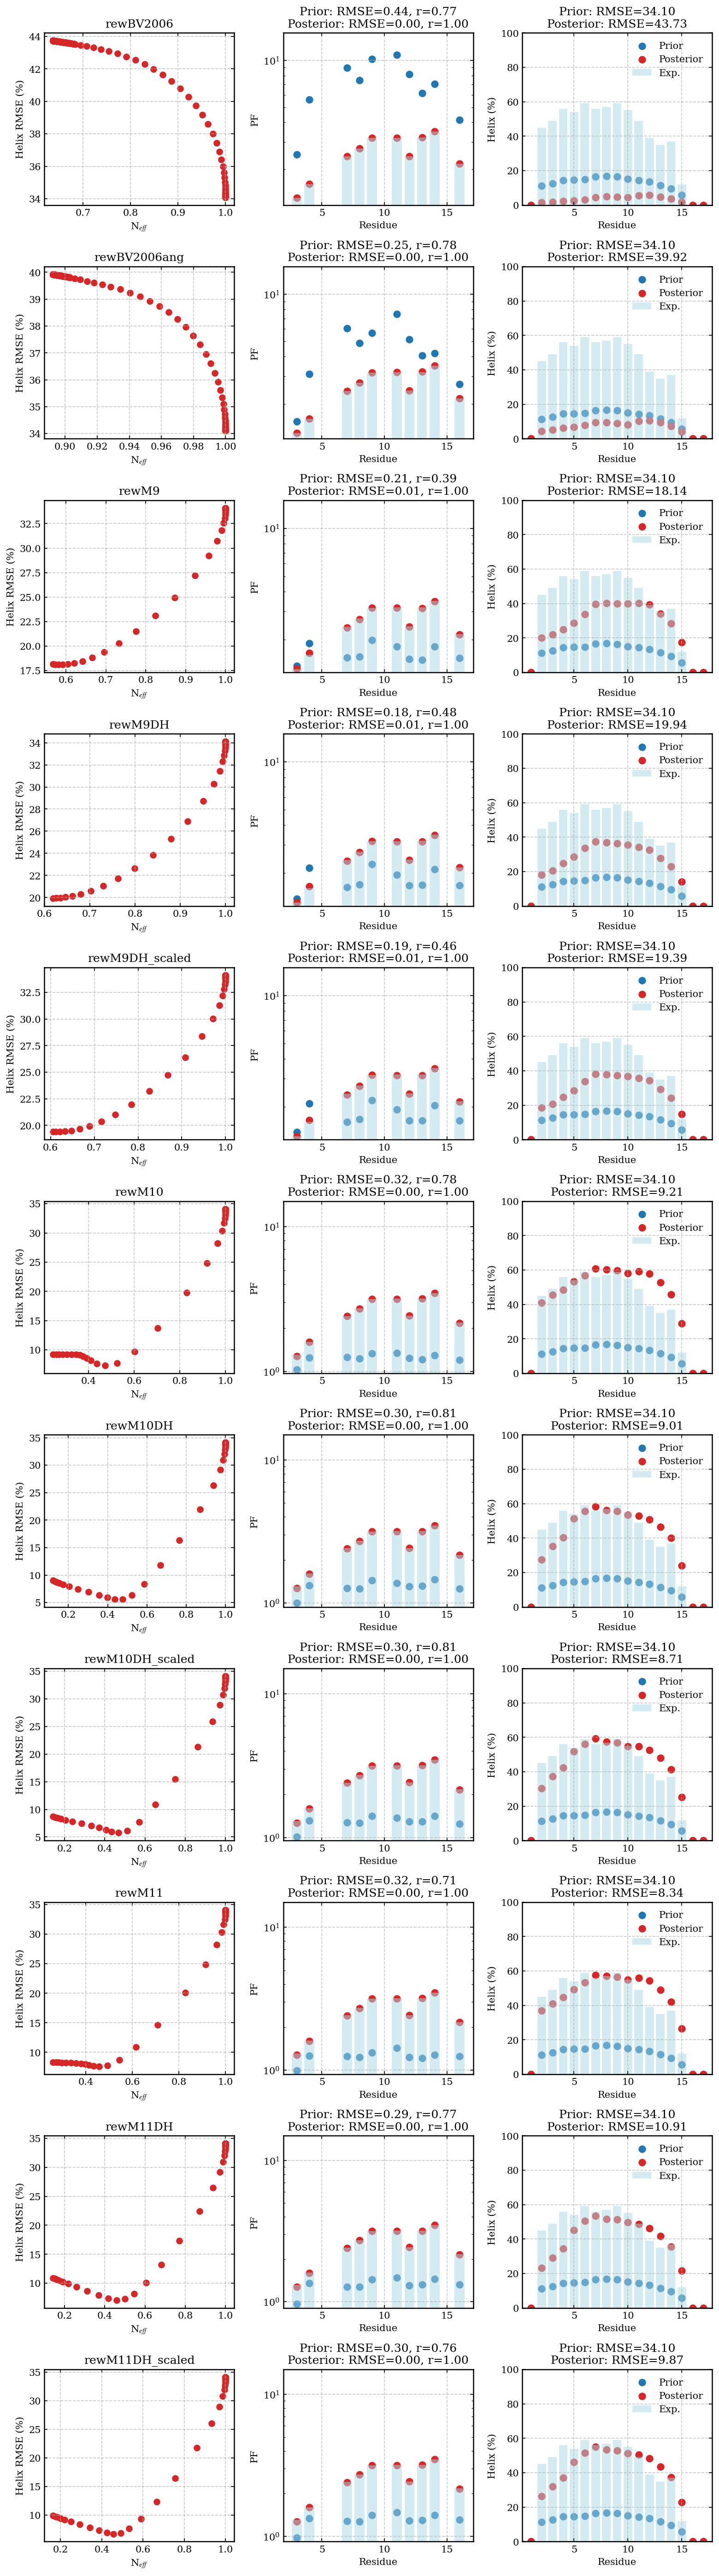

In [3]:
models = ['rewBV2006', 'rewBV2006ang', 'rewM9', 'rewM9DH', 'rewM9DH_scaled', 'rewM10', 'rewM10DH', 'rewM10DH_scaled', 'rewM11', 'rewM11DH', 'rewM11DH_scaled']
protein = 'AAQAA3'

n_models = len(models)
ncols=3
fig, axes = plt.subplots(nrows=n_models, ncols=ncols, figsize=(ncols*3.5, 3.5 * n_models))

# load dssp data
with open(f'../../MD_DATA/{protein}/dssp.dat') as f:
    dssp = [line.strip() for line in f]
dssp =  np.array(dssp)
H = dssp_to_helicity(dssp)*100

# experimental helicity
exp_helix = np.loadtxt('../../ORTHOGONAL_EXP_DATA/AAQAA3/helicity.dat')
exp_helix_residues = exp_helix[:,0].astype(int)

all_residues = np.arange(1,18)


for i, model in enumerate(models):
    exp, residues, priorPF, rewPF, chi2, phi, thetas, stats, idxs = load_pf_data(protein, model_name=model)
    if 'BV' in model:
        wopt_array = np.load(f"../../MD_DATA/{protein}/{model}/wopt_array.npy")
        wopt = np.load(f"../../MD_DATA/{protein}/{model}/wopt.npy")
    else:
        wopt_array = np.load(f"../../MD_DATA/{protein}/{model}/log_lambda_wopt_array.npy")
        wopt = np.load(f"../../MD_DATA/{protein}/{model}/log_lambda_wopt.npy")

    helix_indices = np.array([list(all_residues).index(res) for res in exp_helix_residues])

    expPF = np.array(exp["PF"][idxs])
    rmse_prior = RMSE(np.log10(expPF), np.log10(priorPF))
    rmse_post = RMSE(np.log10(expPF), np.log10(rewPF))
    r_prior = scipy.stats.pearsonr(np.log10(expPF), np.log10(priorPF))[0]
    r_post = scipy.stats.pearsonr(np.log10(expPF), np.log10(rewPF))[0]

    # calculate RMSE to validation data
    validation_rmse = []
    for W in wopt_array:
        avgH = np.average(H,weights=W,axis=0)
        validation_rmse.append(RMSE(avgH[helix_indices], exp_helix[:,1]))

    # --- Plot 1: neff vs RMSE with validation data ---
    ax = axes[i, 0]
    ax.scatter(phi, validation_rmse, c="tab:red")
    ax.set_xlabel("N$_{eff}$"); ax.set_ylabel("Helix RMSE (%)")
    ax.set_title(f"{model}")

    # --- Plot 2: Per-residue PFs ---
    ax = axes[i, 1]
    ax.set_title(f"Prior: RMSE={rmse_prior:.2f}, r={r_prior:.2f}\nPosterior: RMSE={rmse_post:.2f}, r={r_post:.2f}")
    ax.bar(residues, expPF, color="lightblue", alpha=0.5, label="Exp.")
    ax.scatter(residues, priorPF, color="tab:blue", linewidth=1.8, label="Prior")
    ax.scatter(residues, rewPF, color="tab:red", linewidth=1.8, label="Posterior")
    ax.set_yscale("log")
    ax.set_ylim(0,15)
    ax.set_xlabel("Residue"); ax.set_ylabel("PF")

    # --- Plot 3: helicity profile prior and posterior vs experiment ---

    ax = axes[i, 2]
    prior_helicity = np.mean(H,axis=0)
    post_helicity = np.average(H,weights=wopt,axis=0)
    prior_validation_rmse = RMSE(prior_helicity[helix_indices], exp_helix[:,1])
    post_validation_rmse = RMSE(post_helicity[helix_indices], exp_helix[:,1])
    ax.set_title(f"Prior: RMSE={prior_validation_rmse:.2f}\nPosterior: RMSE={validation_rmse[-1]:.2f}")
    ax.bar(exp_helix[:,0], exp_helix[:,1], color="lightblue", alpha=0.5, label="Exp.")
    ax.scatter(all_residues, prior_helicity, color="tab:blue", linewidth=1.8, label="Prior")
    ax.scatter(all_residues, post_helicity, color="tab:red", linewidth=1.8, label="Posterior")
    ax.set_ylim(0,100)
    ax.set_xlabel("Residue"); ax.set_ylabel("Helix (%)")
    ax.legend(loc='upper right')
    
plt.tight_layout(rect=[0, 0, 1, 0.97])
plt.savefig(f"AAQAA3_HDXrew_cross_validation.png", dpi=200, bbox_inches="tight")
    
    


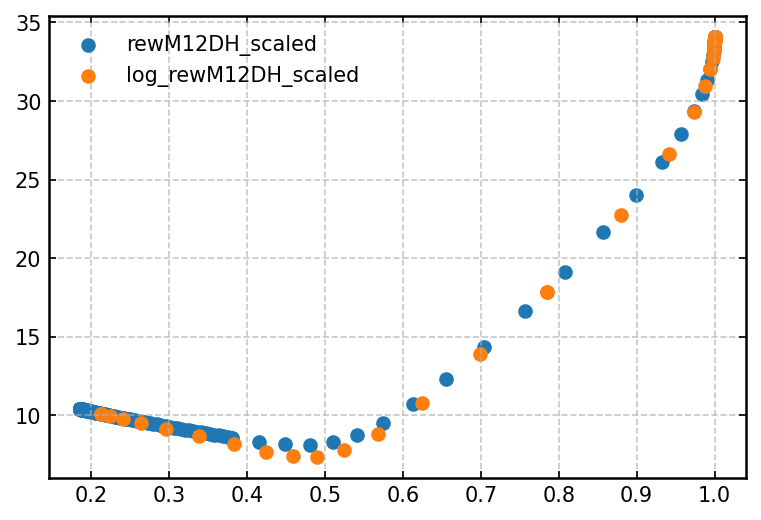

In [3]:
plt.scatter(all_phi[0], all_helix[0], label='rewM12DH_scaled')
plt.scatter(all_phi[1], all_helix[1], label='log_rewM12DH_scaled')
plt.legend()
plt.show()

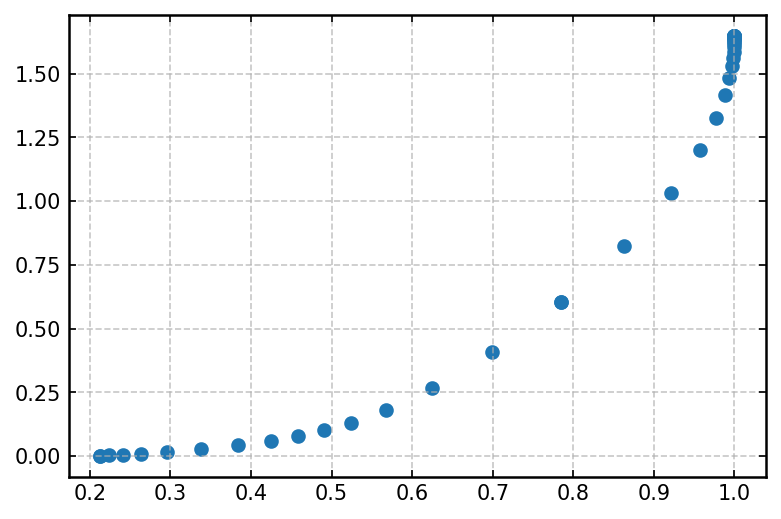

In [23]:
plt.scatter(phi, chi2)

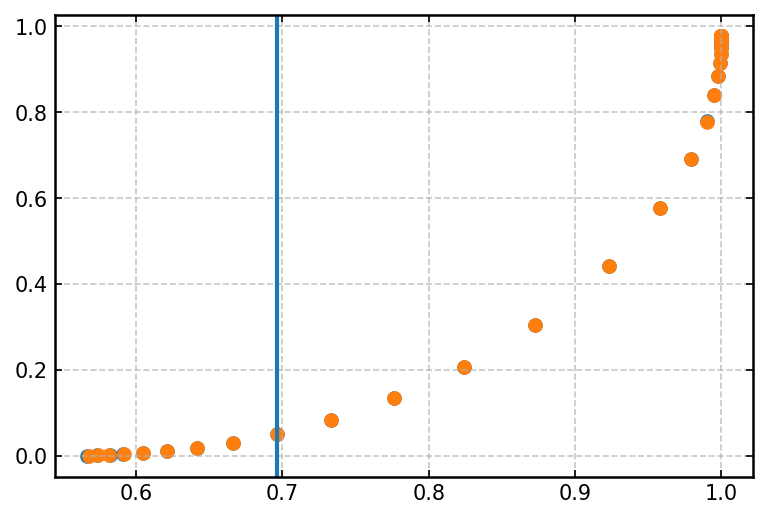

In [16]:
dat1 = np.loadtxt('../../MD_DATA/AAQAA3/rewM9/reweighting_chi2_phi_theta.txt')
dat2 = np.loadtxt('../../MD_DATA/AAQAA3/rewM9/log_reweighting_chi2_phi_theta.txt')
dat3 = np.loadtxt('../../MD_DATA/AAQAA3/rewM9/log_lambda_reweighting_chi2_phi_theta.txt')

#plt.scatter(dat1[1,:], dat1[0,:])
plt.scatter(dat2[1,:], dat2[0,:])
plt.scatter(dat3[1,:], dat3[0,:])
plt.axvline(dat2[1,:][-9])

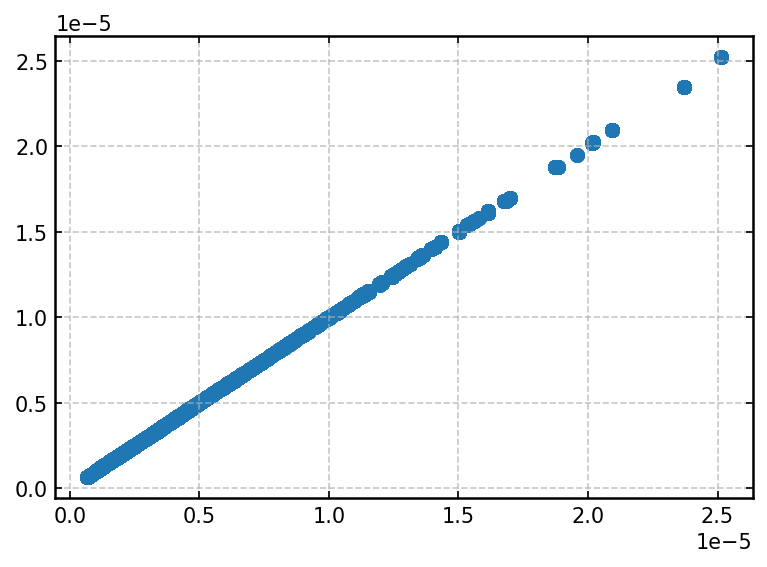

In [15]:
idx = -9

wopt_array1 = np.load('../../MD_DATA/AAQAA3/rewM9/log_wopt_array.npy')
wopt_array2 = np.load('../../MD_DATA/AAQAA3/rewM9/log_lambda_wopt_array.npy')

plt.scatter(wopt_array1[idx], wopt_array2[idx])

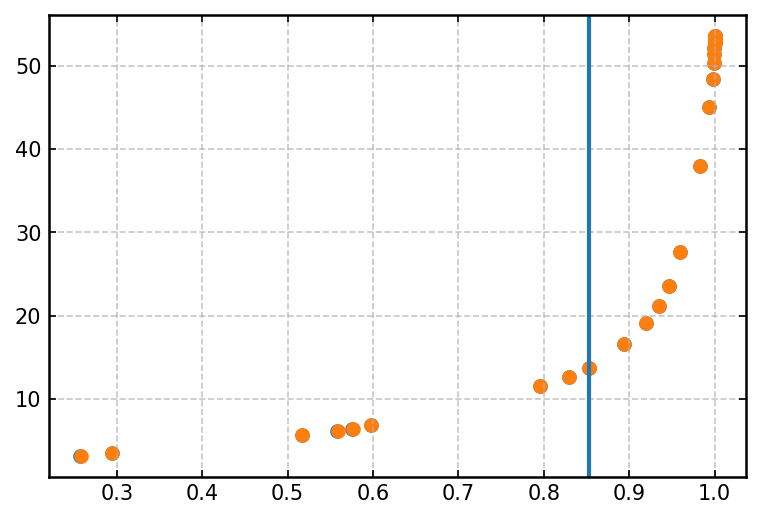

In [29]:
# check EEHEE_rd4_0642-6xHis
dat1 = np.loadtxt('../../../Rocklin_NMRHDX/MD_DATA/EEHEE_rd4_0642-6xHis/rewM9/reweighting_chi2_phi_theta.txt')
dat2 = np.loadtxt('../../../Rocklin_NMRHDX/MD_DATA/EEHEE_rd4_0642-6xHis/rewM9/log_reweighting_chi2_phi_theta.txt')
dat3 = np.loadtxt('../../../Rocklin_NMRHDX/MD_DATA/EEHEE_rd4_0642-6xHis/rewM9/log_lambda_reweighting_chi2_phi_theta.txt')

#plt.scatter(dat1[1,:], dat1[0,:])
plt.scatter(dat2[1,:], dat2[0,:])
plt.scatter(dat3[1,:], dat3[0,:])
plt.axvline(dat2[1,:][-9])

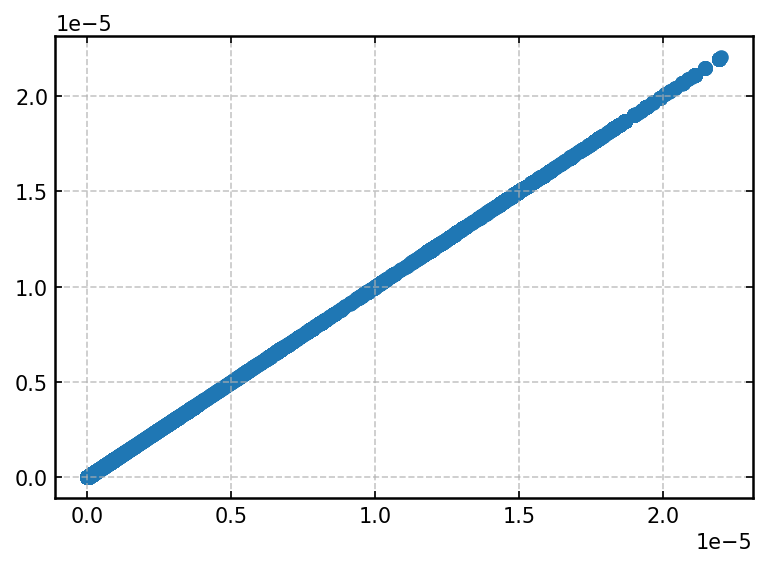

In [28]:
idx = -9
wopt_array1 = np.load('../../../Rocklin_NMRHDX/MD_DATA/EEHEE_rd4_0642-6xHis/rewM9/log_wopt_array.npy')
wopt_array2 = np.load('../../../Rocklin_NMRHDX/MD_DATA/EEHEE_rd4_0642-6xHis/rewM9/log_lambda_wopt_array.npy')

plt.scatter(wopt_array1[idx], wopt_array2[idx])

In [47]:
PF = 1e4
PF_error = PF *0.5
calc = 1e1

lnPF = np.log(PF)
lnPF_err = PF_error/PF
calc_lnPF = np.log(calc)

fopen = 1/PF
fopen_error = PF_error/(PF**2)
calc_fopen = 1/calc

print('chi2 lnPF: ', ((lnPF-calc_lnPF)/lnPF_err)**2)
print('chi2 fopen: ', ((fopen-calc_fopen)/fopen_error)**2)

chi2 lnPF:  190.86833197722237
chi2 fopen:  3992004.0


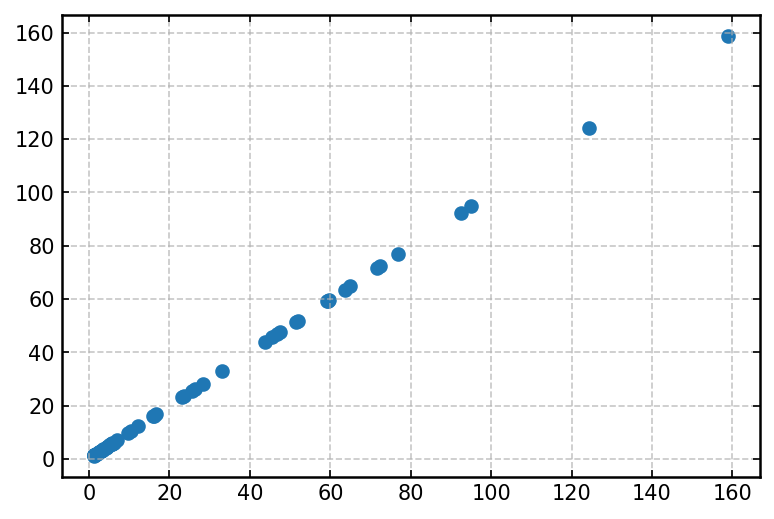

In [50]:
O1 = np.load('../../../Rocklin_NMRHDX/MD_DATA/EEHEE_rd4_0642-6xHis/rewM9/fopen.npy')
O2 = np.load('../../../Rocklin_NMRHDX/MD_DATA/EEHEE_rd4_0642-6xHis/rewM9DH/fopenDH.npy')
res = np.loadtxt('../../../Rocklin_NMRHDX/MD_DATA/EEHEE_rd4_0642-6xHis/rewM9/amideresidues.txt').astype(int)

PF1 = 1/np.mean(O1, axis=0)
O2_mod = (O2!=0)*1
PF2 = 1/np.mean(O2_mod, axis=0)

plt.scatter(PF1,PF2)